# Neural Network Example

Build a 2-hidden layers fully connected neural network (a.k.a multilayer
perceptron) with JAX, using Flax 'layers' and 'model' API.

Flax (NNX) is the neural network library of the JAX ecosystem, the JAX
counterpart of Keras: it provides ready-made layers (`nnx.Linear`,
`nnx.Conv`, ...) and a `nnx.Module` class to assemble them into a model.
The optimizer comes from Optax, the JAX library of optimizers.

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

## Neural Network Overview

<img src="http://cs231n.github.io/assets/nn1/neural_net2.jpeg" alt="nn" style="width: 400px;"/>

## MNIST Dataset Overview

This example is using MNIST handwritten digits. The dataset contains 60,000 examples for training and 10,000 examples for testing. The digits have been size-normalized and centered in a fixed-size image (28x28 pixels) with values from 0 to 255.

In this example, each image will be converted to float32, normalized to [0, 1] and flattened to a 1-D array of 784 features (28*28).

![MNIST Dataset](http://neuralnetworksanddeeplearning.com/images/mnist_100_digits.png)

More info: http://yann.lecun.com/exdb/mnist/

In [1]:
import os
import sys

import jax.numpy as jnp
import numpy as np
import optax
from flax import nnx

# Make the shared helpers of the 'common' folder importable.
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from common.datasets import load_mnist, batch_iterator

In [2]:
# MNIST dataset parameters.
num_classes = 10  # total classes (0-9 digits).
num_features = 784  # data features (img shape: 28*28).

# Training parameters.
learning_rate = 0.1
training_steps = 2000
batch_size = 256
display_step = 100

# Network parameters.
n_hidden_1 = 128  # 1st layer number of neurons.
n_hidden_2 = 256  # 2nd layer number of neurons.

In [3]:
# Prepare MNIST data.
(x_train, y_train), (x_test, y_test) = load_mnist()
# Convert to float32.
x_train, x_test = np.array(x_train, np.float32), np.array(x_test, np.float32)
# Flatten images to 1-D vector of 784 features (28*28).
x_train, x_test = x_train.reshape([-1, num_features]), x_test.reshape([-1, num_features])
# Normalize images value from [0, 255] to [0, 1].
x_train, x_test = x_train / 255., x_test / 255.

In [4]:
# Shuffle and batch data (a simple data loader, see 'common/datasets.py').
train_data = batch_iterator(x_train, y_train, batch_size)

In [5]:
# Create Flax Model.
class NeuralNet(nnx.Module):
    # Set layers.
    # 'rngs' provides the random keys used to initialize the layers weights.
    def __init__(self, rngs):
        # First fully-connected hidden layer.
        self.fc1 = nnx.Linear(num_features, n_hidden_1, rngs=rngs)
        # Second fully-connected hidden layer.
        self.fc2 = nnx.Linear(n_hidden_1, n_hidden_2, rngs=rngs)
        # Output fully-connected layer, with a neuron for each class.
        self.out = nnx.Linear(n_hidden_2, num_classes, rngs=rngs)

    # Set forward pass.
    def __call__(self, x):
        x = nnx.relu(self.fc1(x))
        x = nnx.relu(self.fc2(x))
        # Return the raw scores (logits): the loss function applies softmax.
        return self.out(x)

# Build neural network model.
neural_net = NeuralNet(rngs=nnx.Rngs(0))

In [6]:
# Cross-Entropy Loss.
# Note that this will apply 'softmax' to the logits.
def cross_entropy_loss(x, y):
    # Apply softmax to logits and compute cross-entropy.
    loss = optax.softmax_cross_entropy_with_integer_labels(logits=x, labels=y)
    # Average loss across the batch.
    return jnp.mean(loss)

# Accuracy metric.
def accuracy(y_pred, y_true):
    # Predicted class is the index of highest score in prediction vector (i.e. argmax).
    correct_prediction = jnp.equal(jnp.argmax(y_pred, 1), y_true)
    return jnp.mean(correct_prediction.astype(jnp.float32))

# Stochastic gradient descent optimizer.
# 'wrt=nnx.Param' tells the optimizer to update all the model parameters.
optimizer = nnx.Optimizer(neural_net, optax.sgd(learning_rate), wrt=nnx.Param)

In [7]:
# Optimization process.
# @nnx.jit compiles the function with XLA, so it runs much faster
# (see '1_Introduction/transformations.py').
@nnx.jit
def run_optimization(neural_net, optimizer, x, y):
    # Define the loss as a function of the model, to differentiate it.
    def loss_fn(neural_net):
        # Forward pass.
        pred = neural_net(x)
        # Compute loss.
        return cross_entropy_loss(pred, y)

    # Compute gradients of the loss with respect to the model parameters.
    gradients = nnx.grad(loss_fn)(neural_net)

    # Update the model parameters following gradients.
    optimizer.update(neural_net, gradients)

In [8]:
# Run training for the given number of steps.
for step in range(1, training_steps + 1):
    # Get the next batch of data.
    batch_x, batch_y = next(train_data)
    # Run the optimization to update the model parameters.
    run_optimization(neural_net, optimizer, batch_x, batch_y)

    if step % display_step == 0:
        pred = neural_net(batch_x)
        loss = cross_entropy_loss(pred, batch_y)
        acc = accuracy(pred, batch_y)
        print("step: %i, loss: %f, accuracy: %f" % (step, loss, acc))

step: 100, loss: 0.487344, accuracy: 0.863281
step: 200, loss: 0.288868, accuracy: 0.902344
step: 300, loss: 0.235885, accuracy: 0.929688


step: 400, loss: 0.301741, accuracy: 0.929688
step: 500, loss: 0.203721, accuracy: 0.945312
step: 600, loss: 0.191777, accuracy: 0.945312


step: 700, loss: 0.134691, accuracy: 0.964844
step: 800, loss: 0.124864, accuracy: 0.964844
step: 900, loss: 0.172612, accuracy: 0.953125


step: 1000, loss: 0.221662, accuracy: 0.949219
step: 1100, loss: 0.168091, accuracy: 0.972656
step: 1200, loss: 0.129023, accuracy: 0.960938


step: 1300, loss: 0.127783, accuracy: 0.957031
step: 1400, loss: 0.145525, accuracy: 0.960938
step: 1500, loss: 0.176015, accuracy: 0.949219


step: 1600, loss: 0.127514, accuracy: 0.960938
step: 1700, loss: 0.112789, accuracy: 0.964844
step: 1800, loss: 0.124659, accuracy: 0.968750


step: 1900, loss: 0.073420, accuracy: 0.988281
step: 2000, loss: 0.085646, accuracy: 0.968750


In [9]:
# Test model on validation set.
pred = neural_net(x_test)
print("Test Accuracy: %f" % accuracy(pred, y_test))

Test Accuracy: 0.965700


In [10]:
# Visualize predictions.
import matplotlib.pyplot as plt

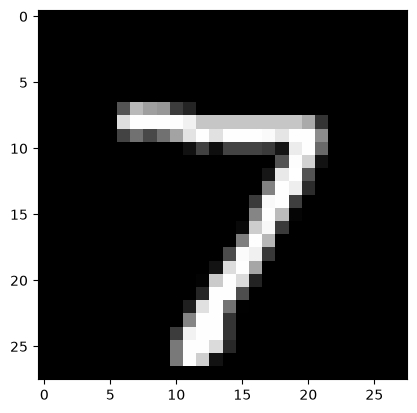

Model prediction: 7


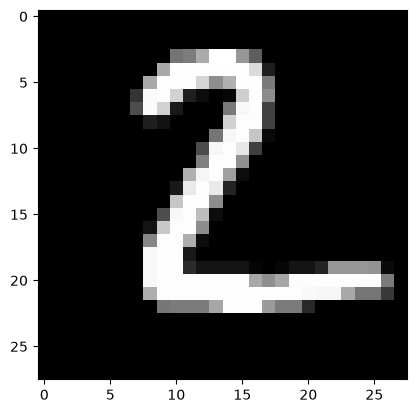

Model prediction: 2


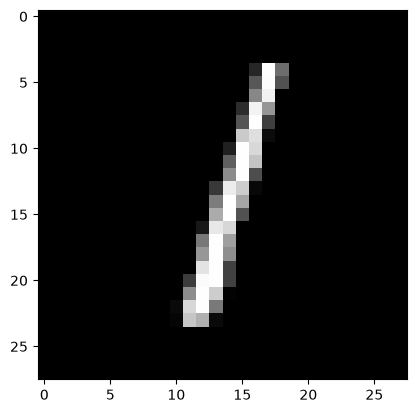

Model prediction: 1


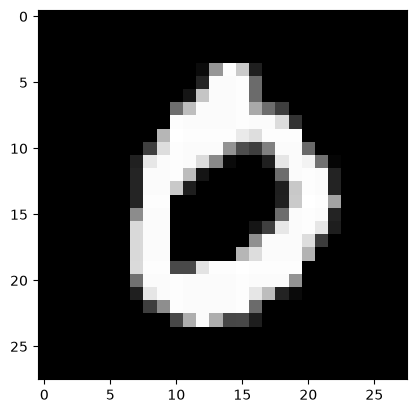

Model prediction: 0


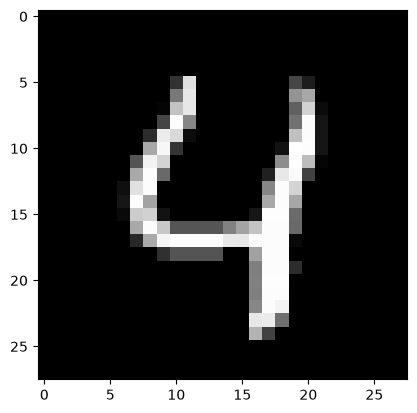

Model prediction: 4


In [11]:
# Predict 5 images from validation set.
n_images = 5
test_images = x_test[:n_images]
predictions = neural_net(test_images)

# Display image and model prediction.
for i in range(n_images):
    plt.imshow(np.reshape(test_images[i], [28, 28]), cmap='gray')
    plt.show()
    print("Model prediction: %i" % np.argmax(predictions[i]))